In [1]:
from pathlib import Path
import json
import random
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

print("PyTorch:", torch.__version__)
print("Torchvision imported successfully.")


C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.0+cu130
Torchvision imported successfully.


## 1. Confirming CUDA is being used

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

PyTorch: 2.14.0+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2. Keeping seeds fixed for reproducibility


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Seed:", SEED)


Seed: 42


## 3. Locating the project


In [5]:
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]

    for candidate in candidates:
        if (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Could not find pyproject.toml."
    )

PROJECT_ROOT = find_project_root()

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "baseline_resnet50"
FIGURE_DIR = REPORT_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)


Project root: D:\UTS\Courseworks\Year2\Semester4\36127InnovationLabCapstoneProject\Development\AutoVision_Model_Development\AutoVision Model Development


## 4. Locating the processed csv file


In [6]:
CSV_CANDIDATES = [
    DATA_DIR / "interim" / "compcars_modeling_ready.csv",
    DATA_DIR / "processed" / "compcars_modeling_ready.csv",
    DATA_DIR / "raw" / "compcars_modeling_ready.csv",
    PROJECT_ROOT / "compcars_modeling_ready.csv",
]

CSV_PATH = next((p for p in CSV_CANDIDATES if p.exists()), None)

if CSV_PATH is None:
    raise FileNotFoundError(
        "compcars_modeling_ready.csv was not found."
    )

print("CSV:", CSV_PATH)


CSV: D:\UTS\Courseworks\Year2\Semester4\36127InnovationLabCapstoneProject\Development\AutoVision_Model_Development\AutoVision Model Development\data\processed\compcars_modeling_ready.csv


## 5. Configure the CompCars image location


In [8]:
LOCAL_COMPCARS_EXTRACTED = Path(
    r"H:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\compcars_kaggle\extracted"
)

if not LOCAL_COMPCARS_EXTRACTED.exists():
    raise FileNotFoundError(
        f"Local CompCars folder does not exist:\n{LOCAL_COMPCARS_EXTRACTED}\n\n"
    )

print("Local CompCars root:", LOCAL_COMPCARS_EXTRACTED)
print("Image folder exists:", (LOCAL_COMPCARS_EXTRACTED / "image").exists())


Local CompCars root: H:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\compcars_kaggle\extracted
Image folder exists: True


## 6. Loading the modelling-ready CSV


In [9]:
df = pd.read_csv(CSV_PATH)

print("Rows:", f"{len(df):,}")
print("Columns:", df.columns.tolist())
display(df.head())

required_columns = {"file_path", "make", "model_name"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"CSV is missing required columns: {sorted(missing)}")


Rows: 135,419
Columns: ['file_path', 'make', 'model_name', 'body_type', 'width', 'height', 'source_dataset', 'image_hash']


,file_path,make,model_name,body_type,width,height,source_dataset,image_hash
0,/content/drive/MyDrive/capstone-vehicle-metada...,Peugeot,Peugeot SR1,NaN,908,626,compcars,25fa9e56ca4f5bb9e73ffe779a101a98
1,/content/drive/MyDrive/capstone-vehicle-metada...,Peugeot,Peugeot SR1,NaN,908,626,compcars,8558bc2cb0192cc1e11465b874225d58
2,/content/drive/MyDrive/capstone-vehicle-metada...,Peugeot,Peugeot SR1,NaN,800,567,compcars,ac30b864ce7e76e4af2b230754b85ec1
3,/content/drive/MyDrive/capstone-vehicle-metada...,Peugeot,Peugeot SR1,NaN,800,567,compcars,efb05d59635584496daac973569dd50e
4,/content/drive/MyDrive/capstone-vehicle-metada...,Peugeot,Peugeot SR1,NaN,800,567,compcars,62e2ef440fb1a950464ad160c16169b8


## 7. Converting Colab image paths to local Windows paths



In [10]:
def resolve_local_path(original_path: str) -> Path:
    text = str(original_path).replace("\\", "/")

    markers = [
        "/extracted/",
        "/compcars_local/",
    ]

    for marker in markers:
        if marker in text:
            relative = text.split(marker, 1)[1]
            return LOCAL_COMPCARS_EXTRACTED / Path(*relative.split("/"))

    if "/image/" in text:
        relative = "image/" + text.split("/image/", 1)[1]
        return LOCAL_COMPCARS_EXTRACTED / Path(*relative.split("/"))

    return Path(original_path)


df["local_file_path"] = df["file_path"].map(resolve_local_path)

display(df[["file_path", "local_file_path"]].head(3))


,file_path,local_file_path
0,/content/drive/MyDrive/capstone-vehicle-metada...,H:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_s...
1,/content/drive/MyDrive/capstone-vehicle-metada...,H:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_s...
2,/content/drive/MyDrive/capstone-vehicle-metada...,H:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_s...


## 8. Verifying that the images actually exist locally

In [11]:
PATH_CHECK_SAMPLE = min(500, len(df))

check_df = df.sample(PATH_CHECK_SAMPLE, random_state=SEED).copy()
check_df["exists"] = check_df["local_file_path"].map(Path.exists)

print(f"Checked {PATH_CHECK_SAMPLE} random paths")
print(f"Existing: {check_df['exists'].sum()}")
print(f"Missing: {(~check_df['exists']).sum()}")

if not check_df["exists"].all():
    display(check_df.loc[~check_df["exists"], ["file_path", "local_file_path"]].head(10))
    raise FileNotFoundError(
        "Some image paths do not resolve locally. Fix LOCAL_COMPCARS_EXTRACTED "
        "before continuing."
    )

print("Path mapping looks good.")


Checked 500 random paths
Existing: 500
Missing: 0
Path mapping looks good.


## 9. Inspecting model-level class distribution

In [12]:
classification_df = df.dropna(subset=["make", "model_name"]).copy()

classification_df["class_name"] = (
    classification_df["make"].astype(str).str.strip()
    + " | "
    + classification_df["model_name"].astype(str).str.strip()
)

class_counts = classification_df["class_name"].value_counts()

print("Usable make/model rows:", f"{len(classification_df):,}")
print("Unique make/model classes:", f"{classification_df['class_name'].nunique():,}")
print()
print(class_counts.describe())

thresholds = [20, 50, 100, 200, 300, 500]
for threshold in thresholds:
    print(
        f"Classes with >= {threshold:>3} images:",
        int((class_counts >= threshold).sum())
    )


Usable make/model rows: 135,419
Unique make/model classes: 1,667

count    1667.000000
mean       81.235153
std        47.673622
min         1.000000
25%        33.000000
50%       102.000000
75%       120.000000
max       303.000000
Name: count, dtype: float64
Classes with >=  20 images: 1425
Classes with >=  50 images: 1104
Classes with >= 100 images: 839
Classes with >= 200 images: 11
Classes with >= 300 images: 1
Classes with >= 500 images: 0


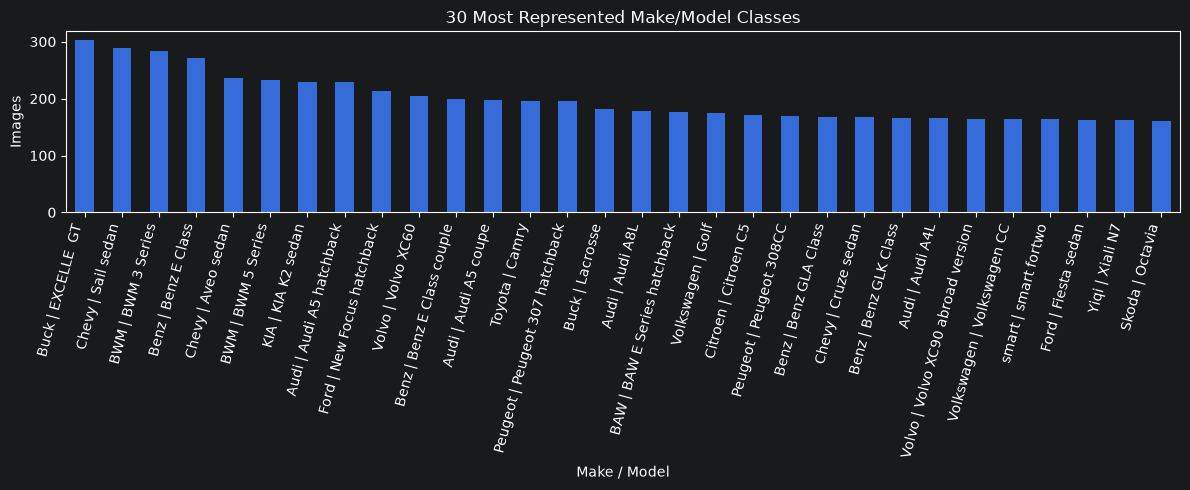

In [13]:
plt.figure(figsize=(12, 5))
class_counts.head(30).plot(kind="bar")
plt.title("30 Most Represented Make/Model Classes")
plt.xlabel("Make / Model")
plt.ylabel("Images")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


## 10. Selecting the baseline subset


In [15]:
TOP_N_CLASSES = 20
MIN_IMAGES_PER_CLASS = 100
MAX_IMAGES_PER_CLASS = 100

eligible_counts = class_counts[class_counts >= MIN_IMAGES_PER_CLASS]

if len(eligible_counts) < TOP_N_CLASSES:
    raise ValueError(
        f"Only {len(eligible_counts)} classes have >= "
        f"{MIN_IMAGES_PER_CLASS} images."
    )

selected_classes = eligible_counts.head(TOP_N_CLASSES).index.tolist()

eligible_df = classification_df[
    classification_df["class_name"].isin(selected_classes)
].copy()

baseline_df = (
    eligible_df
    .groupby("class_name", group_keys=False)
    .sample(n=MAX_IMAGES_PER_CLASS, random_state=SEED)
    .reset_index(drop=True)
)

baseline_counts = baseline_df["class_name"].value_counts()

print("Selected classes:", len(selected_classes))
print("Baseline images:", f"{len(baseline_df):,}")
print("Minimum class size:", baseline_counts.min())
print("Maximum class size:", baseline_counts.max())

display(baseline_counts.to_frame("images"))

Selected classes: 20
Baseline images: 2,000
Minimum class size: 100
Maximum class size: 100


,images
class_name,
Audi | Audi A5 coupe,100
Audi | Audi A5 hatchback,100
Audi | Audi A8L,100
BAW | BAW E Series hatchback,100
BWM | BWM 3 Series,100
BWM | BWM 5 Series,100
Benz | Benz E Class,100
Benz | Benz E Class couple,100
Buck | EXCELLE GT,100


## 11. Viewing some baseline images

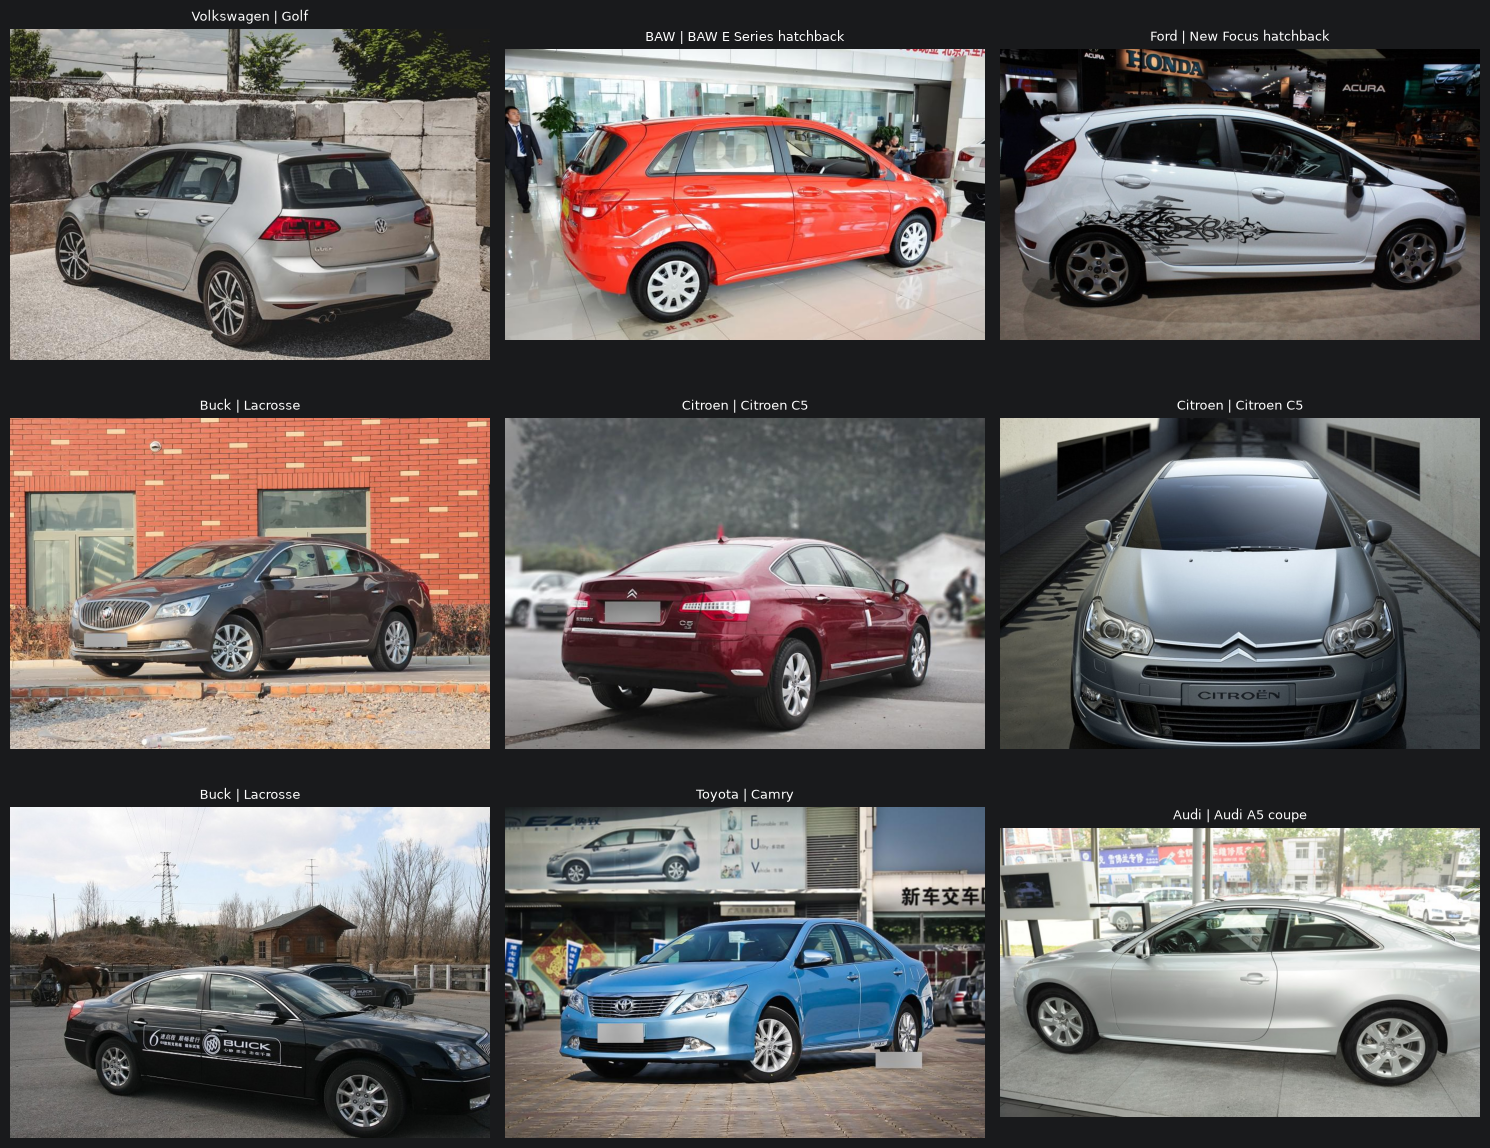

In [16]:
sample = baseline_df.sample(9, random_state=SEED)

plt.figure(figsize=(15, 12))

for plot_index, (_, row) in enumerate(sample.iterrows(), start=1):
    image = Image.open(row["local_file_path"]).convert("RGB")

    plt.subplot(3, 3, plot_index)
    plt.imshow(image)
    plt.title(row["class_name"], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


## 12. Encoding classes and creating a stratified train/validation/test split


In [17]:
label_encoder = LabelEncoder()
baseline_df["target"] = label_encoder.fit_transform(baseline_df["class_name"])

train_df, temp_df = train_test_split(
    baseline_df,
    test_size=0.20,
    random_state=SEED,
    stratify=baseline_df["target"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["target"],
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Classes:", len(label_encoder.classes_))

for name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(
        f"{name}: min/class={split_df['target'].value_counts().min()}, "
        f"max/class={split_df['target'].value_counts().max()}"
    )


Train: 1600
Validation: 200
Test: 200
Classes: 20
train: min/class=80, max/class=80
val: min/class=10, max/class=10
test: min/class=10, max/class=10


In [34]:
split_dir = DATA_DIR / "interim"
split_dir.mkdir(parents=True, exist_ok=True)

split_manifest = pd.concat(
    [
        train_df.assign(split="train"),
        val_df.assign(split="val"),
        test_df.assign(split="test"),
    ],
    ignore_index=True,
)

split_manifest = split_manifest.drop(
    columns=["local_file_path"],
    errors="ignore"
)

BASELINE_MANIFEST_PATH = split_dir / "compcars_resnet50_baseline_split.csv"
split_manifest.to_csv(BASELINE_MANIFEST_PATH, index=False)

print("Saved:", BASELINE_MANIFEST_PATH)

Saved: D:\UTS\Courseworks\Year2\Semester4\36127InnovationLabCapstoneProject\Development\AutoVision_Model_Development\AutoVision Model Development\data\interim\compcars_resnet50_baseline_split.csv


## 13. Image preprocessing


In [19]:
IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.80, 1.0),
        ratio=(0.85, 1.15),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


## 14. PyTorch dataset

In [20]:
class CompCarsClassificationDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, transform=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(row["local_file_path"]).convert("RGB")
        target = int(row["target"])

        if self.transform is not None:
            image = self.transform(image)

        return image, target


train_dataset = CompCarsClassificationDataset(train_df, train_transform)
val_dataset = CompCarsClassificationDataset(val_df, eval_transform)
test_dataset = CompCarsClassificationDataset(test_df, eval_transform)

len(train_dataset), len(val_dataset), len(test_dataset)


(1600, 200, 200)

## 15. Setting up DataLoaders

In [21]:
BATCH_SIZE = 16
NUM_WORKERS = 0

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    **loader_kwargs,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_kwargs,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs,
)

images, targets = next(iter(train_loader))

print("Batch image tensor:", images.shape)
print("Batch targets:", targets.shape)
print("Batch size:", BATCH_SIZE)


Batch image tensor: torch.Size([16, 3, 224, 224])
Batch targets: torch.Size([16])
Batch size: 16


## 16. Building the pretrained ResNet50 baseline



In [22]:
NUM_CLASSES = len(label_encoder.classes_)

weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

for parameter in model.parameters():
    parameter.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(DEVICE)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print("Classes:", NUM_CLASSES)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters (stage 1): {trainable_params:,}")
print("Model device:", next(model.parameters()).device)


Classes: 20
Total parameters: 23,549,012
Trainable parameters (stage 1): 40,980
Model device: cuda:0


## 17. Training/evaluation utilities

In [23]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

scaler = torch.amp.GradScaler("cuda", enabled=True)

def topk_correct(logits, targets, k=5):
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices
    return topk.eq(targets.view(-1, 1)).any(dim=1).sum().item()


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    running_loss = 0.0
    correct_top1 = 0
    correct_top5 = 0
    samples = 0

    for images, targets in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True,
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        correct_top1 += (logits.argmax(dim=1) == targets).sum().item()
        correct_top5 += topk_correct(logits, targets, k=5)
        samples += batch_size

    return {
        "loss": running_loss / samples,
        "top1": correct_top1 / samples,
        "top5": correct_top5 / samples,
    }


def train_epochs(model, train_loader, val_loader, optimizer, epochs, stage_name):
    history = []
    best_state = None
    best_val_top1 = -1.0

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        train_metrics = run_epoch(model, train_loader, optimizer)

        with torch.inference_mode():
            val_metrics = run_epoch(model, val_loader)

        elapsed = time.perf_counter() - start

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_top1": train_metrics["top1"],
            "train_top5": train_metrics["top5"],
            "val_loss": val_metrics["loss"],
            "val_top1": val_metrics["top1"],
            "val_top5": val_metrics["top5"],
            "seconds": elapsed,
        }
        history.append(row)

        print(
            f"[{stage_name}] Epoch {epoch:02d}/{epochs} | "
            f"train loss={row['train_loss']:.4f} "
            f"top1={row['train_top1']:.3f} | "
            f"val loss={row['val_loss']:.4f} "
            f"top1={row['val_top1']:.3f} "
            f"top5={row['val_top5']:.3f} | "
            f"{elapsed:.1f}s"
        )

        if row["val_top1"] > best_val_top1:
            best_val_top1 = row["val_top1"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return history


## 18. Stage 1: Training the classification head



In [24]:
STAGE1_EPOCHS = 3

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

history_stage1 = train_epochs(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=STAGE1_EPOCHS,
    stage_name="head",
)


[head] Epoch 01/3 | train loss=2.7847 top1=0.206 | val loss=2.5848 top1=0.380 top5=0.750 | 2527.0s


[head] Epoch 02/3 | train loss=2.2880 top1=0.515 | val loss=2.3036 top1=0.440 top5=0.830 | 40.0s


[head] Epoch 03/3 | train loss=1.9692 top1=0.672 | val loss=2.1792 top1=0.460 top5=0.850 | 39.3s


## 19. Stage 2: Finetuning the final ResNet block


In [25]:
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters (stage 2): {trainable_params:,}")

STAGE2_EPOCHS = 3

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-4,
)

history_stage2 = train_epochs(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=STAGE2_EPOCHS,
    stage_name="layer4_finetune",
)


Trainable parameters (stage 2): 15,005,716


[layer4_finetune] Epoch 01/3 | train loss=1.4520 top1=0.751 | val loss=1.5145 top1=0.705 top5=0.940 | 48.6s


[layer4_finetune] Epoch 02/3 | train loss=0.9261 top1=0.956 | val loss=1.3957 top1=0.735 top5=0.950 | 41.2s


[layer4_finetune] Epoch 03/3 | train loss=0.7780 top1=0.987 | val loss=1.3162 top1=0.760 top5=0.965 | 42.5s


## 20. Plotting training history

,stage,epoch,train_loss,train_top1,train_top5,val_loss,val_top1,val_top5,seconds
0,head,1,2.784745,0.206250,0.556250,2.584798,0.380,0.750,2526.988612
1,head,2,2.287996,0.515000,0.868125,2.303552,0.440,0.830,40.013051
2,head,3,1.969230,0.671875,0.933750,2.179248,0.460,0.850,39.335099
3,layer4_finetune,1,1.451962,0.750625,0.961875,1.514490,0.705,0.940,48.581908
4,layer4_finetune,2,0.926104,0.956250,0.999375,1.395710,0.735,0.950,41.160193
5,layer4_finetune,3,0.777986,0.986875,1.000000,1.316233,0.760,0.965,42.484062


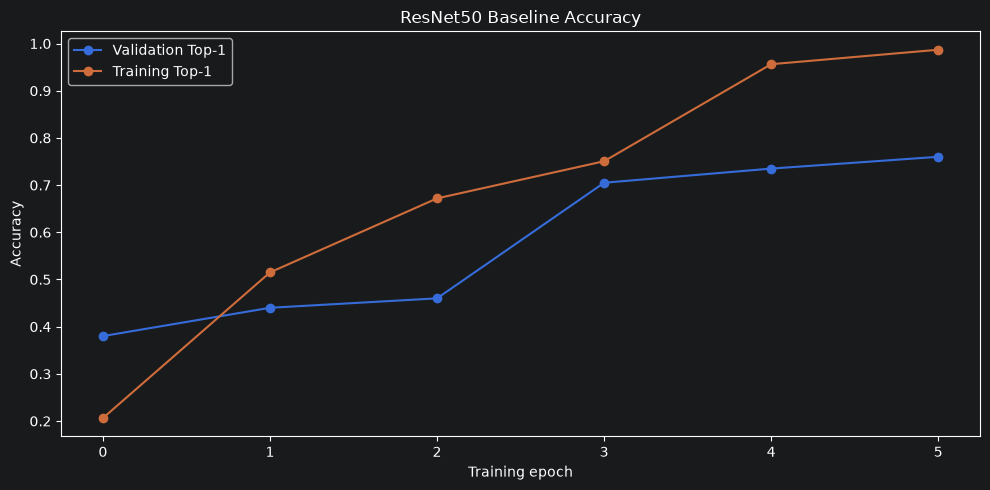

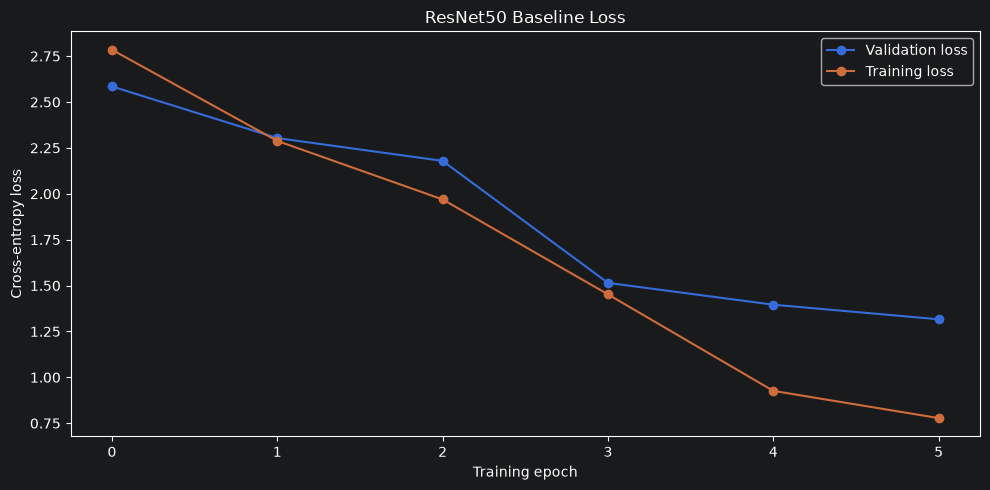

In [26]:
history = pd.DataFrame(history_stage1 + history_stage2)
display(history)

history.to_csv(REPORT_DIR / "training_history.csv", index=False)

plt.figure(figsize=(10, 5))
plt.plot(history["val_top1"].values, marker="o", label="Validation Top-1")
plt.plot(history["train_top1"].values, marker="o", label="Training Top-1")
plt.xlabel("Training epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Baseline Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "accuracy_curve.png", dpi=160)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history["val_loss"].values, marker="o", label="Validation loss")
plt.plot(history["train_loss"].values, marker="o", label="Training loss")
plt.xlabel("Training epoch")
plt.ylabel("Cross-entropy loss")
plt.title("ResNet50 Baseline Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "loss_curve.png", dpi=160)
plt.show()


## 21. Test evaluation on the heldout dataset


In [27]:
def collect_predictions(model, loader):
    model.eval()

    all_targets = []
    all_predictions = []
    all_probabilities = []

    with torch.inference_mode():
        for images, targets in tqdm(loader):
            images = images.to(DEVICE, non_blocking=True)

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)

            all_targets.extend(targets.numpy())
            all_predictions.extend(probabilities.argmax(dim=1).cpu().numpy())
            all_probabilities.append(probabilities.cpu())

    return (
        np.asarray(all_targets),
        np.asarray(all_predictions),
        torch.cat(all_probabilities, dim=0),
    )


y_true, y_pred, probabilities = collect_predictions(model, test_loader)

top1 = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

top5_indices = probabilities.topk(
    min(5, NUM_CLASSES),
    dim=1
).indices.numpy()

top5 = np.mean([
    true_target in predicted_top5
    for true_target, predicted_top5 in zip(y_true, top5_indices)
])

print(f"Test Top-1 accuracy: {top1:.4f}")
print(f"Test Top-5 accuracy: {top5:.4f}")
print(f"Test Macro F1:       {macro_f1:.4f}")


100%|﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿| 13/13 [04:50<00:00, 22.34s/it]

Test Top-1 accuracy: 0.8100
Test Top-5 accuracy: 0.9950
Test Macro F1:       0.8108


In [28]:
report = classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T
report_df.to_csv(REPORT_DIR / "classification_report.csv")

display(report_df)


,precision,recall,f1-score,support
Audi | Audi A5 coupe,0.500000,0.70,0.583333,10.00
Audi | Audi A5 hatchback,0.600000,0.30,0.400000,10.00
Audi | Audi A8L,0.750000,0.90,0.818182,10.00
BAW | BAW E Series hatchback,1.000000,0.80,0.888889,10.00
BWM | BWM 3 Series,0.909091,1.00,0.952381,10.00
BWM | BWM 5 Series,1.000000,0.90,0.947368,10.00
Benz | Benz E Class,0.700000,0.70,0.700000,10.00
Benz | Benz E Class couple,0.562500,0.90,0.692308,10.00
Buck | EXCELLE GT,0.818182,0.90,0.857143,10.00
Buck | Lacrosse,1.000000,0.80,0.888889,10.00


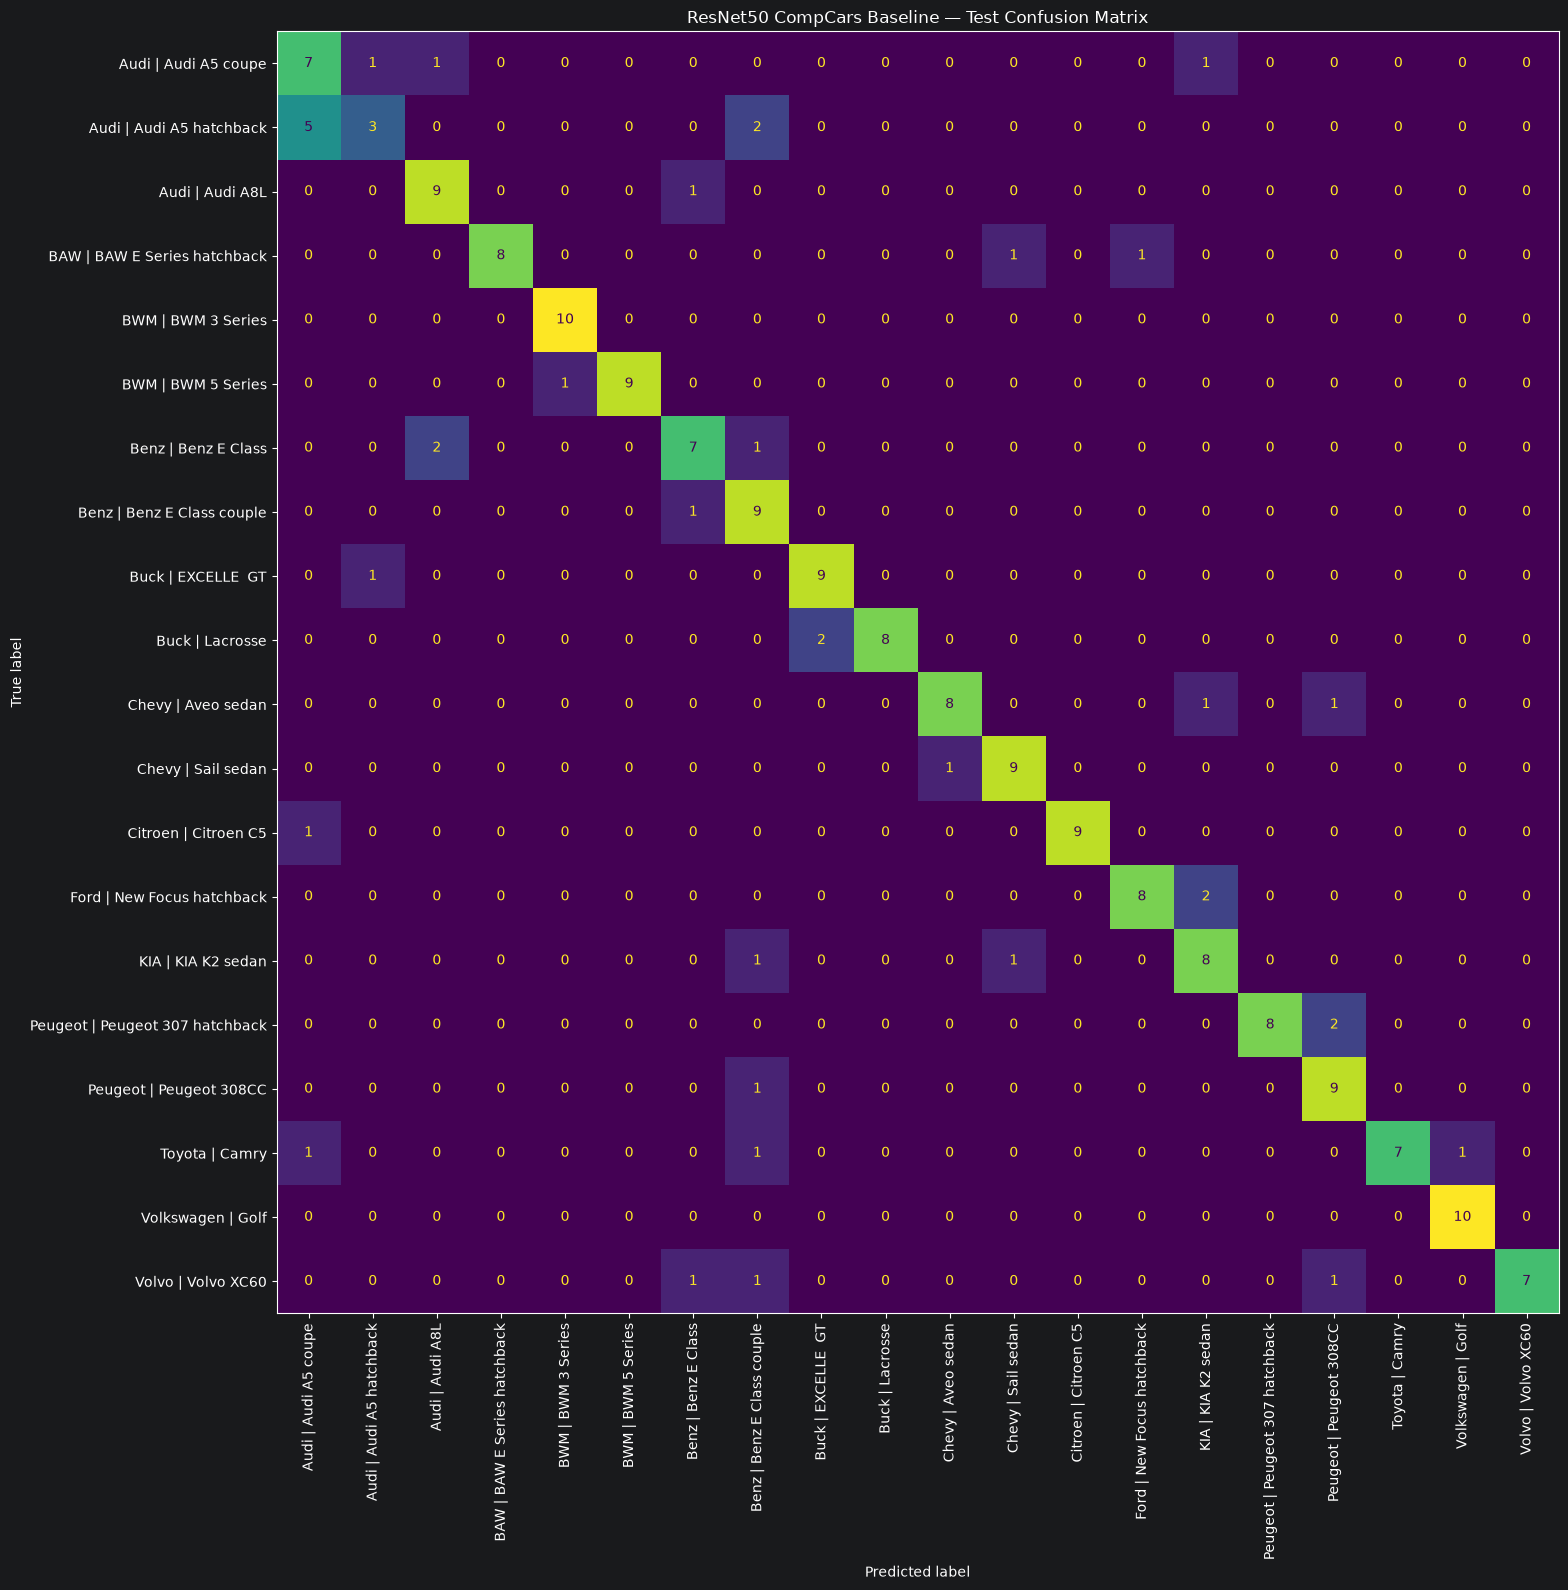

In [29]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(16, 16))
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_,
)
display_cm.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d",
)
ax.set_title("ResNet50 CompCars Baseline ﷿﷿﷿ Test Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "confusion_matrix.png", dpi=160)
plt.show()


## 22. Inspecting individual predictions and confidence

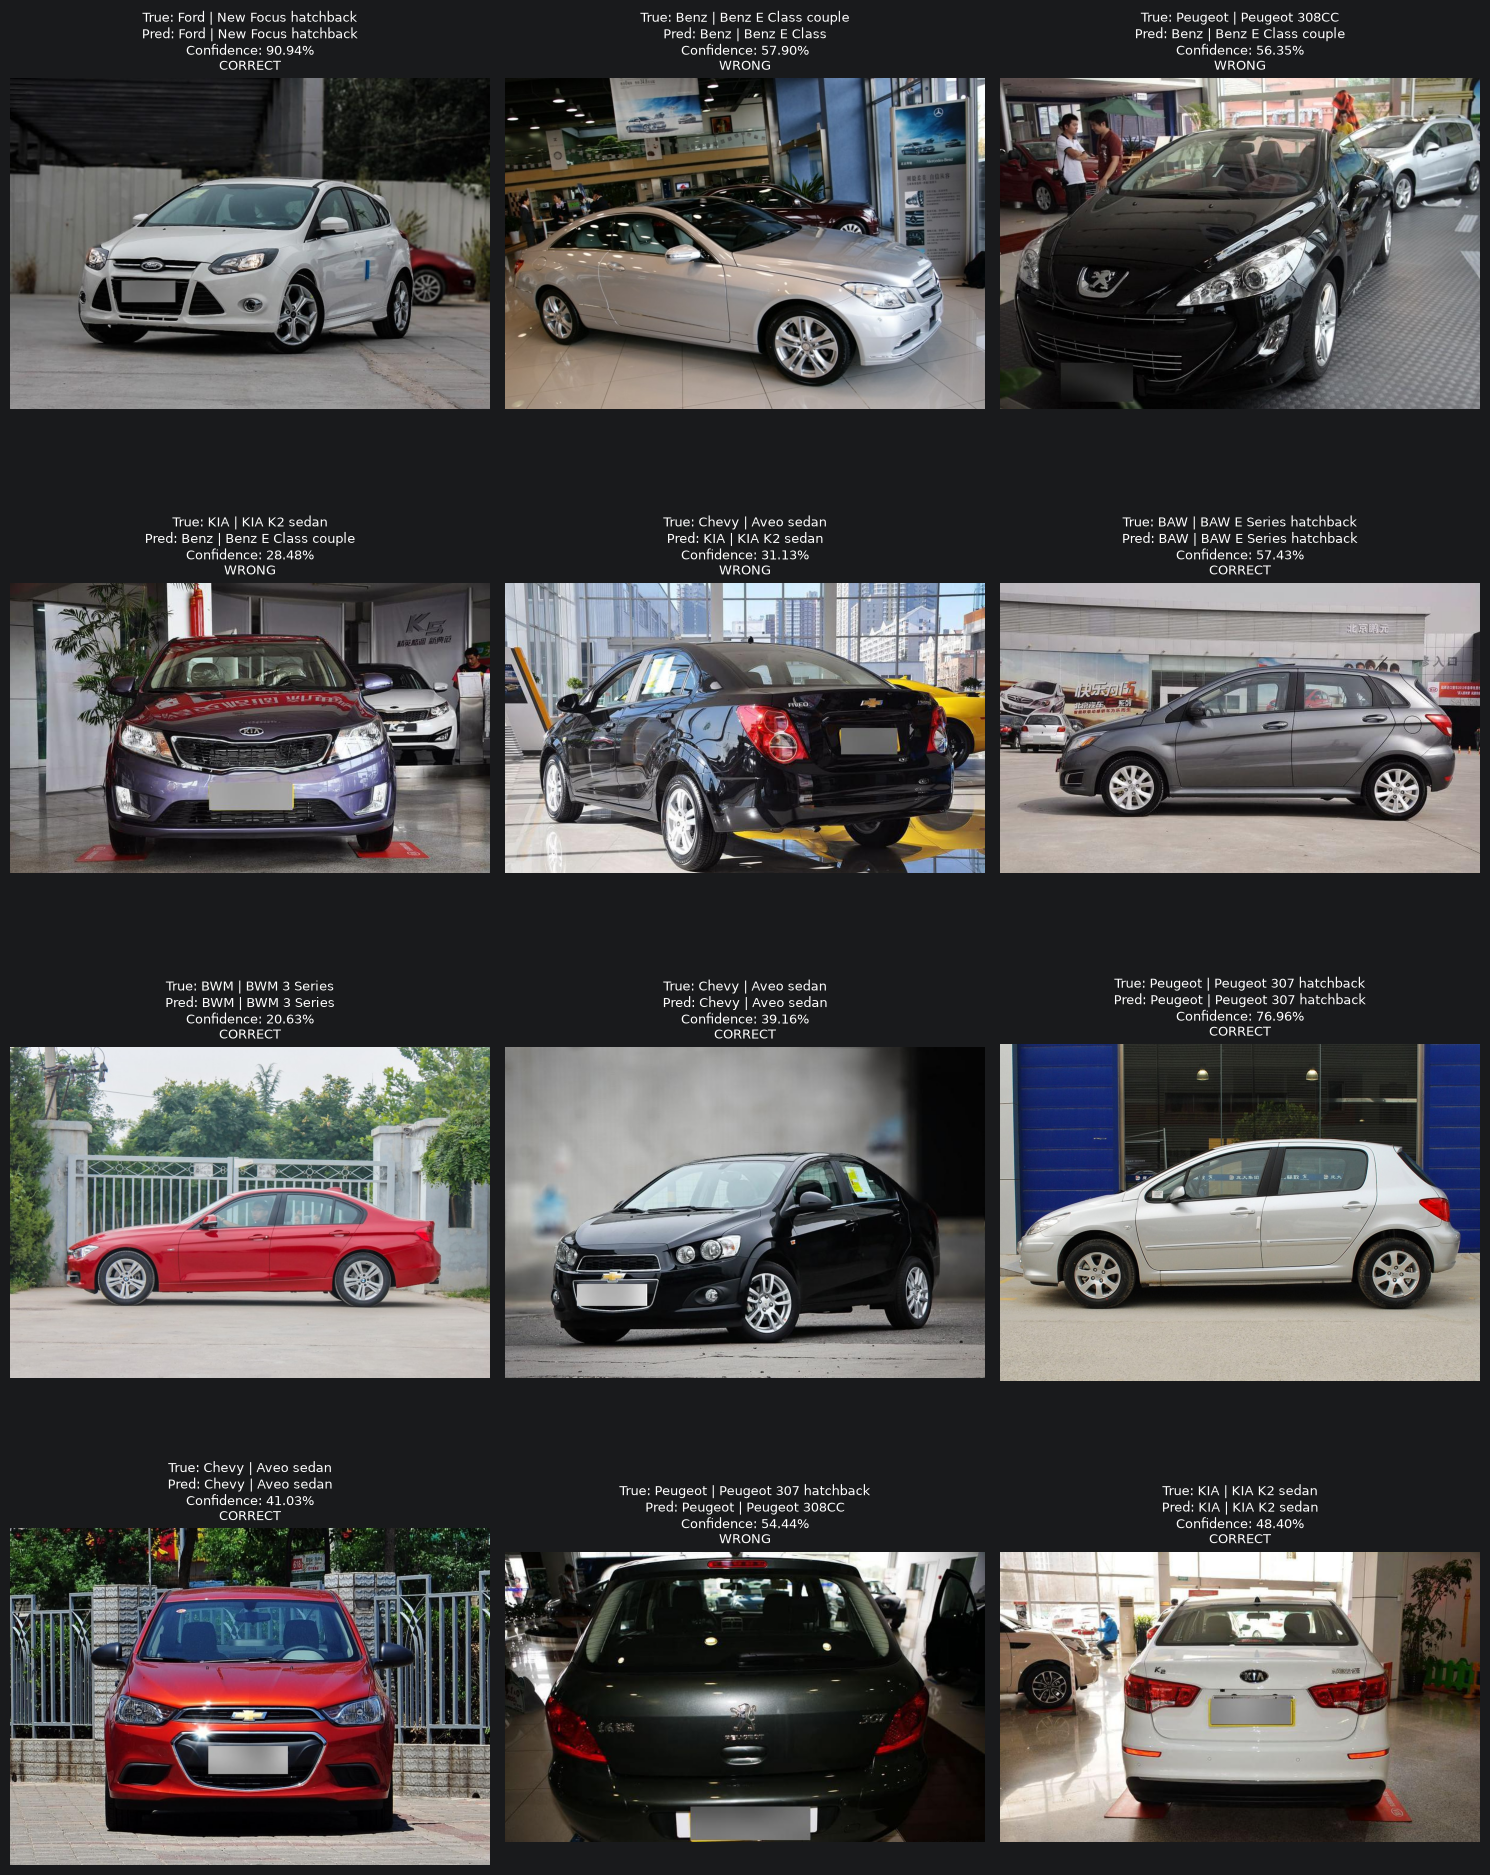

In [30]:
def show_test_predictions(n=12, random_state=SEED):
    local_test_df = test_df.reset_index(drop=True)
    sample_indices = (
        local_test_df
        .sample(min(n, len(local_test_df)), random_state=random_state)
        .index
        .tolist()
    )

    cols = 3
    rows = int(np.ceil(len(sample_indices) / cols))

    plt.figure(figsize=(15, 5 * rows))

    model.eval()
    for plot_number, dataframe_index in enumerate(sample_indices, start=1):
        row = local_test_df.iloc[dataframe_index]
        image = Image.open(row["local_file_path"]).convert("RGB")

        tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            logits = model(tensor)
            probs = torch.softmax(logits, dim=1)[0]

        confidence, predicted_index = probs.max(dim=0)
        predicted_label = label_encoder.inverse_transform(
            [predicted_index.item()]
        )[0]

        plt.subplot(rows, cols, plot_number)
        plt.imshow(image)

        correct = predicted_label == row["class_name"]

        plt.title(
            f"True: {row['class_name']}\n"
            f"Pred: {predicted_label}\n"
            f"Confidence: {confidence.item():.2%}\n"
            f"{'CORRECT' if correct else 'WRONG'}",
            fontsize=9,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_test_predictions()


## 23. Saving the baseline model and experiment metadata

In [31]:
MODEL_PATH = MODEL_DIR / "resnet50_compcars_baseline.pt"

checkpoint = {
    "architecture": "resnet50",
    "task": "make_model_classification",
    "image_size": IMAGE_SIZE,
    "classes": label_encoder.classes_.tolist(),
    "num_classes": NUM_CLASSES,
    "state_dict": model.state_dict(),
    "seed": SEED,
    "top_n_classes": TOP_N_CLASSES,
    "min_images_per_class": MIN_IMAGES_PER_CLASS,
    "max_images_per_class": MAX_IMAGES_PER_CLASS,
    "test_top1": float(top1),
    "test_top5": float(top5),
    "test_macro_f1": float(macro_f1),
    "gpu": gpu_name,
}

torch.save(checkpoint, MODEL_PATH)

metrics = {
    "architecture": "ResNet50",
    "pretraining": "ImageNet",
    "classes": NUM_CLASSES,
    "training_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "test_top1_accuracy": float(top1),
    "test_top5_accuracy": float(top5),
    "test_macro_f1": float(macro_f1),
    "gpu": gpu_name,
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
}

with (REPORT_DIR / "metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved reports:", REPORT_DIR)


Saved model: D:\UTS\Courseworks\Year2\Semester4\36127InnovationLabCapstoneProject\Development\AutoVision_Model_Development\AutoVision Model Development\models\resnet50_compcars_baseline.pt
Saved reports: D:\UTS\Courseworks\Year2\Semester4\36127InnovationLabCapstoneProject\Development\AutoVision_Model_Development\AutoVision Model Development\reports\baseline_resnet50
